# Лабораторна робота 8. Перенесення навчання (Transfer Learning): InceptionV3

## Завантаження набору даних з Google Диска

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
import glob, shutil

# шукаємо архів dogs-vs-cats.zip з Kaggle у будь-якій папці Google Диска
found = glob.glob('/content/drive/MyDrive/**/dogs-vs-cats*.zip', recursive=True)
print(found)
assert found, 'Архів dogs-vs-cats.zip не знайдено на Google Диску'
shutil.copy(found[0], '/content/dogs-vs-cats.zip')

['/content/drive/MyDrive/dogs-vs-cats.zip']


'/content/dogs-vs-cats.zip'

In [4]:
# розпаковуємо архів з Kaggle, а потім train.zip з 25 000 зображень
!unzip -q -o /content/dogs-vs-cats.zip -d /content/dogs-vs-cats
!unzip -q -o /content/dogs-vs-cats/train.zip -d /content/dogs-vs-cats
!ls /content/dogs-vs-cats/train | wc -l

25000


## Підготовка набору даних (скрипт prepare_dataset.py з лабораторної роботи 7)

In [5]:
%%writefile prepare_dataset.py
"""Підготовка набору даних Dogs vs. Cats для навчання нейронної мережі в Keras.

Зображення з каталогу data_dir (25 000 файлів cat.N.jpg і dog.N.jpg з Kaggle) розподіляються
на три набори: для навчання (70%), перевірки (15%) і тестування (15%).
У кожному наборі створюються підкаталоги cats і dogs, як потрібно для flow_from_directory.
"""
import os
import shutil

# Каталог з набором даних (розпакований train.zip з Kaggle)
data_dir = '/content/dogs-vs-cats/train'
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Частина набору даних для тестування
test_data_portion = 0.15
# Частина набору даних для перевірки
val_data_portion = 0.15
# Кількість зображень в одному класі
nb_images = 12500


def create_directory(dir_name):
    """Створює каталог dir_name з підкаталогами cats і dogs (старий каталог видаляється)."""
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    """Копіює зображення котів і собак з номерами від start_index до end_index у підкаталоги cats і dogs."""
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, "cat." + str(i) + ".jpg"),
                     os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, "dog." + str(i) + ".jpg"),
                     os.path.join(dest_dir, "dogs"))


create_directory(train_dir)
create_directory(val_dir)
create_directory(test_dir)

# Індекси, з яких починаються набори для перевірки і тестування
start_val_data_idx = int(nb_images * (1 - val_data_portion - test_data_portion))
start_test_data_idx = int(nb_images * (1 - test_data_portion))
print(start_val_data_idx)
print(start_test_data_idx)

copy_images(0, start_val_data_idx, data_dir, train_dir)
copy_images(start_val_data_idx, start_test_data_idx, data_dir, val_dir)
copy_images(start_test_data_idx, nb_images, data_dir, test_dir)

for d in (train_dir, val_dir, test_dir):
    print(d, ': cats -', len(os.listdir(os.path.join(d, "cats"))), ', dogs -', len(os.listdir(os.path.join(d, "dogs"))))

Writing prepare_dataset.py


In [6]:
!python prepare_dataset.py

8750
10625
train : cats - 8750 , dogs - 8750
val : cats - 1875 , dogs - 1875
test : cats - 1875 , dogs - 1875


## Підключаємо бібліотеки

In [7]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import load_img, img_to_array

## Константи

In [8]:
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Розміри зображення
img_width, img_height = 150, 150
# Розмірність тензору на основі зображення для вхідних даних в нейронну мережу
input_shape = (img_width, img_height, 3)
# Кількість епох
epochs = 10
# Розмір міні-вибірки
batch_size = 16

## Генератори зображень

In [9]:
# для InceptionV3 зображення обробляються функцією preprocess_input з модуля inception_v3 (як у документації Keras)
datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# shuffle=False: порядок зображень не перемішується, тому мітки беремо з generator.classes
def make_generator(directory):
    return datagen.flow_from_directory(directory,
                                       target_size=(img_width, img_height),
                                       batch_size=64,
                                       class_mode='binary',
                                       shuffle=False)

train_generator = make_generator(train_dir)
val_generator = make_generator(val_dir)
test_generator = make_generator(test_dir)
print(train_generator.class_indices)

Found 17500 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


## Завантажуємо попередньо навчену мережу InceptionV3 без частини для класифікації

In [10]:
inception_net = InceptionV3(weights='imagenet',
                            include_top=False,
                            input_shape=input_shape)
# згорткову частину не навчаємо
inception_net.trainable = False
print('Шарів у мережі:', len(inception_net.layers))
print('Вихід згорткової частини:', inception_net.output_shape)
print('Параметрів:', inception_net.count_params())

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Шарів у мережі: 311
Вихід згорткової частини: (None, 3, 3, 2048)
Параметрів: 21802784


## Обчислення ознак згорткової частини

In [11]:
# Згорткова частина заморожена і не змінюється під час навчання, тому кожне зображення достатньо
# пропустити через неї один раз і запам'ятати отримані карти ознак
train_features = inception_net.predict(train_generator, verbose=1)
val_features = inception_net.predict(val_generator, verbose=1)
test_features = inception_net.predict(test_generator, verbose=1)
train_labels = train_generator.classes
val_labels = val_generator.classes
test_labels = test_generator.classes
print('Ознаки для навчання:', train_features.shape)
print('Ознаки для перевірки:', val_features.shape)
print('Ознаки для тестування:', test_features.shape)

274/274 ━━━━━━━━━━━━━━━━━━━━ 1031s 4s/step
59/59 ━━━━━━━━━━━━━━━━━━━━ 220s 4s/step
59/59 ━━━━━━━━━━━━━━━━━━━━ 227s 4s/step
Ознаки для навчання: (17500, 3, 3, 2048)
Ознаки для перевірки: (3750, 3, 3, 2048)
Ознаки для тестування: (3750, 3, 3, 2048)


## Новий класифікатор

In [12]:
def create_classifier(dropout_rate):
    """Новий класифікатор для двох класів, як у лекції: Flatten, Dense 256, Dropout, Dense 1."""
    classifier = Sequential()
    classifier.add(Input(shape=train_features.shape[1:]))
    classifier.add(Flatten())
    classifier.add(Dense(256, activation='relu'))
    if dropout_rate > 0:
        classifier.add(Dropout(dropout_rate))
    classifier.add(Dense(1, activation='sigmoid'))
    classifier.compile(loss='binary_crossentropy',
                       optimizer=Adam(learning_rate=1e-5),
                       metrics=['accuracy'])
    return classifier


def build_full_model(net, classifier):
    """Складена мережа: заморожена згорткова частина + навчений класифікатор."""
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(net)
    model.add(classifier)
    return model

In [13]:
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='навчальна')
    plt.plot(epochs_range, val_acc, label='перевірочна')
    plt.title(title + ': точність'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='навчальна')
    plt.plot(epochs_range, val_loss, label='перевірочна')
    plt.title(title + ': помилка (loss)'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.show()

## Навчання з Dropout 0.5

In [14]:
clf = create_classifier(0.5)
clf.summary()

history_clf = clf.fit(train_features, train_labels,
                batch_size=batch_size,
                epochs=epochs,
                validation_data=(val_features, val_labels))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,719,105 (18.00 MB)

 Trainable params: 4,719,105 (18.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 99s 89ms/step - accuracy: 0.9389 - loss: 0.1768 - val_accuracy: 0.9645 - val_loss: 0.0921
Epoch 2/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 138s 86ms/step - accuracy: 0.9676 - loss: 0.0848 - val_accuracy: 0.9659 - val_loss: 0.0875
Epoch 3/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 93s 85ms/step - accuracy: 0.9733 - loss: 0.0699 - val_accuracy: 0.9664 - val_loss: 0.0908
Epoch 4/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 151s 93ms/step - accuracy: 0.9775 - loss: 0.0545 - val_accuracy: 0.9688 - val_loss: 0.0855
Epoch 5/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 95s 87ms/step - accuracy: 0.9842 - loss: 0.0421 - val_accuracy: 0.9688 - val_loss: 0.0902
Epoch 6/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 144s 88ms/step - accuracy: 0.9868 - loss: 0.0351 - val_accuracy: 0.9688 - val_loss: 0.0891
Epoch 7/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 141s 88ms/step - accuracy: 0.9889 - loss: 0.0298 - val_accuracy: 0.9707 - val_loss: 0.0951
Epoch 8/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 151s 96ms/step - accuracy: 0.9

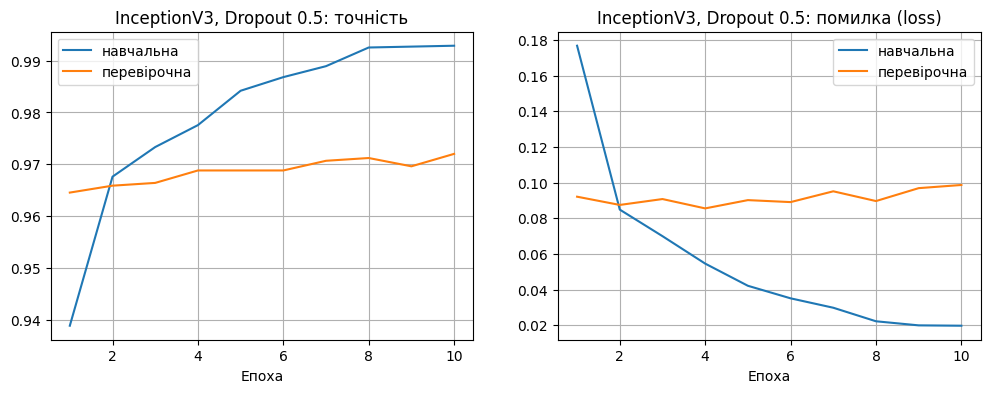

In [15]:
plot_history(history_clf, 'InceptionV3, Dropout 0.5')

In [16]:
scores_clf = clf.evaluate(test_features, test_labels, verbose=0)
print("Точність на тестових даних (InceptionV3, Dropout 0.5): %.2f%%" % (scores_clf[1] * 100))

Точність на тестових даних (InceptionV3, Dropout 0.5): 96.72%


## Збереження моделі на Google Диск

In [17]:
save_dir = '/content/drive/MyDrive/Lab8_models'
os.makedirs(save_dir, exist_ok=True)
best_model = build_full_model(inception_net, clf)
best_model.save(os.path.join(save_dir, 'inceptionv3_dropout05.h5'), include_optimizer=False)
!ls -lh {save_dir}

total 102M
-rw------- 1 root root 102M Oct 23 21:25 inceptionv3_dropout05.h5


## Розпізнавання власних зображень (ті самі, що в лабораторній роботі 7)

In [18]:
# копіюємо зображення з папки images_cats_dogs на Google Диску в робочий каталог
img_dirs = glob.glob('/content/drive/MyDrive/**/images_cats_dogs', recursive=True)
print(img_dirs)
assert img_dirs, 'Папку images_cats_dogs не знайдено на Google Диску'
for f in glob.glob(os.path.join(img_dirs[0], '*.jpg')):
    shutil.copy(f, '/content/')
print(len(glob.glob('/content/*.jpg')), 'зображень')

['/content/drive/MyDrive/Deep learning/images_cats_dogs']
47 зображень


In [19]:
def prepare(x):
    """Обробка зображення для InceptionV3, як у генераторі."""
    return preprocess_input(x)


def recognize(pattern, title):
    """Розпізнає всі зображення, що відповідають шаблону pattern, і показує їх з відповіддю мережі.
    Правильна відповідь береться з назви файлу: cat_... або dog_... (hard_cat_..., crop_dog_... тощо)."""
    names = sorted(glob.glob(pattern))
    cols = 5
    rows = (len(names) + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3.4 * rows), dpi=60)
    correct = 0
    for i, fn in enumerate(names):
        img = load_img(fn, target_size=(img_width, img_height))
        x = prepare(img_to_array(img))                          # така сама обробка, як у генераторі
        x = np.expand_dims(x, axis=0)
        p = float(best_model.predict(x, verbose=0)[0][0])     # ймовірність класу dogs
        pred = 'dog' if p > 0.5 else 'cat'
        true = 'dog' if 'dog' in os.path.basename(fn) else 'cat'
        correct += pred == true
        conf = p if pred == 'dog' else 1 - p
        print(f"{os.path.basename(fn)}: правильно - {true}, мережа - {pred} ({conf*100:.1f}%) {'✓' if pred == true else '✗'}")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(fn)}\n{pred} ({conf*100:.1f}%)", color='green' if pred == true else 'red')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    print(f"Правильно розпізнано: {correct} з {len(names)}")

### 10 котів і 10 собак

cat_01.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_02.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_03.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_04.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_05.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_06.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_07.jpg: правильно - cat, мережа - cat (93.4%) ✓
cat_08.jpg: правильно - cat, мережа - dog (87.8%) ✗
cat_09.jpg: правильно - cat, мережа - cat (99.9%) ✓
cat_10.jpg: правильно - cat, мережа - dog (94.8%) ✗


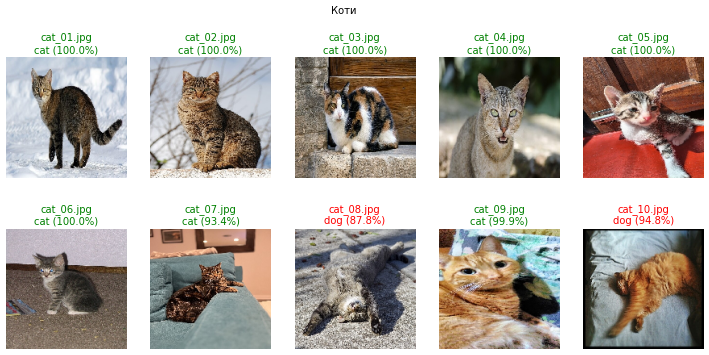

Правильно розпізнано: 8 з 10
dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_02.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_03.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_04.jpg: правильно - dog, мережа - dog (99.9%) ✓
dog_05.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_08.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_09.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_10.jpg: правильно - dog, мережа - dog (100.0%) ✓


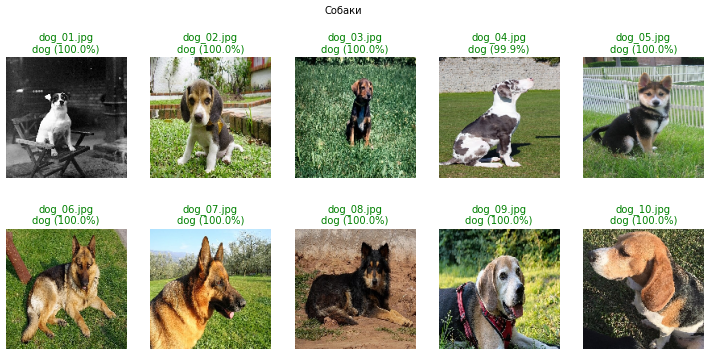

Правильно розпізнано: 10 з 10


In [20]:
recognize('cat_*.jpg', 'Коти')
recognize('dog_*.jpg', 'Собаки')

### Складні зображення

hard_cat_01.jpg: правильно - cat, мережа - cat (58.2%) ✓
hard_cat_02.jpg: правильно - cat, мережа - dog (91.6%) ✗
hard_cat_03.jpg: правильно - cat, мережа - cat (95.1%) ✓
hard_cat_04.jpg: правильно - cat, мережа - cat (54.6%) ✓
hard_cat_05.jpg: правильно - cat, мережа - cat (60.5%) ✓
hard_cat_06.jpg: правильно - cat, мережа - cat (84.8%) ✓
hard_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_08.jpg: правильно - cat, мережа - cat (99.9%) ✓
hard_cat_09.jpg: правильно - cat, мережа - cat (50.3%) ✓
hard_cat_10.jpg: правильно - cat, мережа - cat (89.3%) ✓
hard_dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_02.jpg: правильно - dog, мережа - dog (50.8%) ✓
hard_dog_03.jpg: правильно - dog, мережа - dog (80.7%) ✓
hard_dog_04.jpg: правильно - dog, мережа - dog (85.4%) ✓
hard_dog_05.jpg: правильно - dog, мережа - dog (96.7%) ✓
hard_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_08.jpg: правильно 

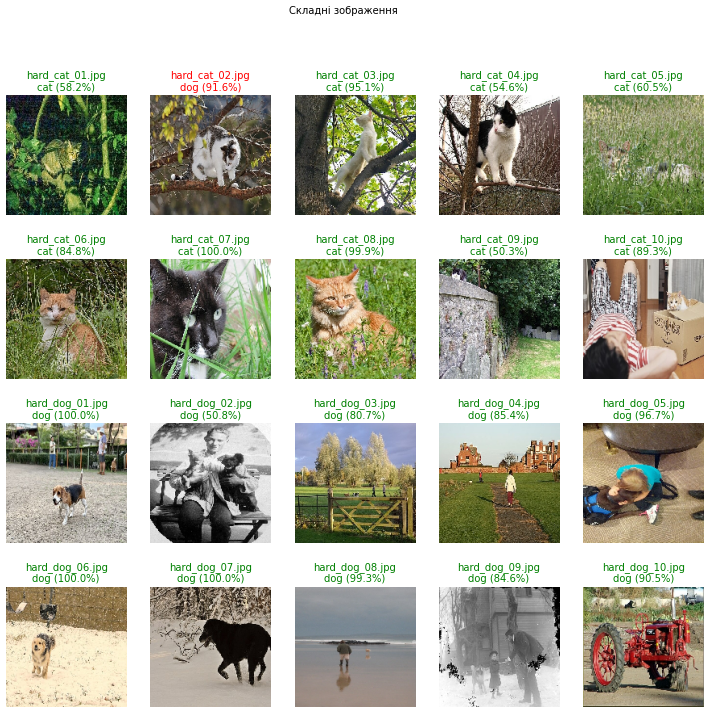

Правильно розпізнано: 19 з 20


In [21]:
recognize('hard_*.jpg', 'Складні зображення')

### Обрізані зображення

crop_cat_02.jpg: правильно - cat, мережа - cat (98.8%) ✓
crop_cat_03.jpg: правильно - cat, мережа - cat (99.0%) ✓
crop_cat_05.jpg: правильно - cat, мережа - dog (50.1%) ✗
crop_cat_06.jpg: правильно - cat, мережа - cat (99.9%) ✓
crop_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_08.jpg: правильно - cat, мережа - cat (96.3%) ✓
crop_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓


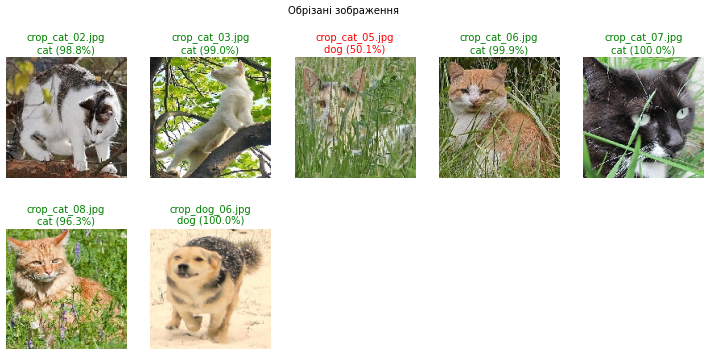

Правильно розпізнано: 6 з 7


In [22]:
recognize('crop_*.jpg', 'Обрізані зображення')